In this section, we import the required libraries and configure pandas display options to facilitate exploratory analysis of the dataset.

In [47]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Visual configuration
sns.set_style("whitegrid")
pd.set_option('display.max_columns', None)

# Load dataset
df = pd.read_csv('../data/raw/candidates.csv', sep=';')

# Quick look
print(f"Dataset dimensions: {df.shape}")
df.head()

Dataset dimensions: (50000, 10)


,First Name,Last Name,Email,Application Date,Country,YOE,Seniority,Technology,Code Challenge Score,Technical Interview Score
0,Bernadette,Langworth,leonard91@yahoo.com,2021-02-26,Norway,2,Intern,Data Engineer,3,3
1,Camryn,Reynolds,zelda56@hotmail.com,2021-09-09,Panama,10,Intern,Data Engineer,2,10
2,Larue,Spinka,okey_schultz41@gmail.com,2020-04-14,Belarus,4,Mid-Level,Client Success,10,9
3,Arch,Spinka,elvera_kulas@yahoo.com,2020-10-01,Eritrea,25,Trainee,QA Manual,7,1
4,Larue,Altenwerth,minnie.gislason@gmail.com,2020-05-20,Myanmar,13,Mid-Level,Social Media Community Management,9,7


We assess data completeness by checking for missing values and cast the `Application Date` column to an appropriate datetime type.

In [48]:
# General information
df.info()

# Convert date column to datetime
df['Application Date'] = pd.to_datetime(df['Application Date'])

# Check for nulls
print("\nNull values per column:")
print(df.isnull().sum())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 50000 entries, 0 to 49999
Data columns (total 10 columns):
 #   Column                     Non-Null Count  Dtype 
---  ------                     --------------  ----- 
 0   First Name                 50000 non-null  object
 1   Last Name                  50000 non-null  object
 2   Email                      50000 non-null  object
 3   Application Date           50000 non-null  object
 4   Country                    50000 non-null  object
 5   YOE                        50000 non-null  int64 
 6   Seniority                  50000 non-null  object
 7   Technology                 50000 non-null  object
 8   Code Challenge Score       50000 non-null  int64 
 9   Technical Interview Score  50000 non-null  int64 
dtypes: int64(3), object(7)
memory usage: 3.8+ MB

Null values per column:
First Name                   0
Last Name                    0
Email                        0
Application Date             0
Country                      0
Y

We analyze duplicate records based on the `Email` field to identify inconsistent identities (a single email associated with multiple candidates). To standardize the dataset, we normalize candidates at the email level, retaining the most recent application as the source of truth for personal information.

In [49]:
# Identify duplicates by Email
duplicates = df[df.duplicated(subset=['Email'], keep=False)].sort_values(by='Email')

print(f"Total applications: {len(df)}")
print(f"Unique candidates (by email): {df['Email'].nunique()}")
print(f"Total duplicated records: {len(duplicates)}")

# Show a specific case to highlight name inconsistencies
# We look for an email that has different first names
inconsistent_candidates = df.groupby('Email')['First Name'].nunique()
inconsistent_emails = inconsistent_candidates[inconsistent_candidates > 1]

print(f"\nNumber of emails with different names across applications: {len(inconsistent_emails)}")

if not inconsistent_emails.empty:
    example_email = inconsistent_emails.index[0]
    print(f"\nExample of inconsistency for email: {example_email}")
    display(df[df['Email'] == example_email][['First Name', 'Last Name', 'Country', 'Application Date', 'Technology']])

Total applications: 50000
Unique candidates (by email): 49833
Total duplicated records: 332

Number of emails with different names across applications: 165

Example of inconsistency for email: abbigail94@yahoo.com


,First Name,Last Name,Country,Application Date,Technology
15823,Herta,Bartoletti,Dominican Republic,2022-02-20,Client Success
31764,Gavin,Brakus,Croatia,2019-07-27,DevOps


We review the distinct values of the `Technology` and `Seniority` fields to confirm their consistency and ensure there are no typographical variants (for example, "DevOps" vs. "devops").


Unique technologies: 24
['Data Engineer' 'Client Success' 'QA Manual'
 'Social Media Community Management' 'Adobe Experience Manager' 'Sales'
 'Mulesoft' 'DevOps' 'Development - CMS Backend' 'Salesforce'
 'System Administration' 'Security' 'Game Development'
 'Development - CMS Frontend' 'Security Compliance'
 'Development - Backend' 'Design'
 'Business Analytics / Project Management' 'Development - Frontend'
 'Development - FullStack' 'Business Intelligence'
 'Database Administration' 'QA Automation' 'Technical Writing']

Unique seniority levels: 7
['Intern' 'Mid-Level' 'Trainee' 'Junior' 'Lead' 'Architect' 'Senior']


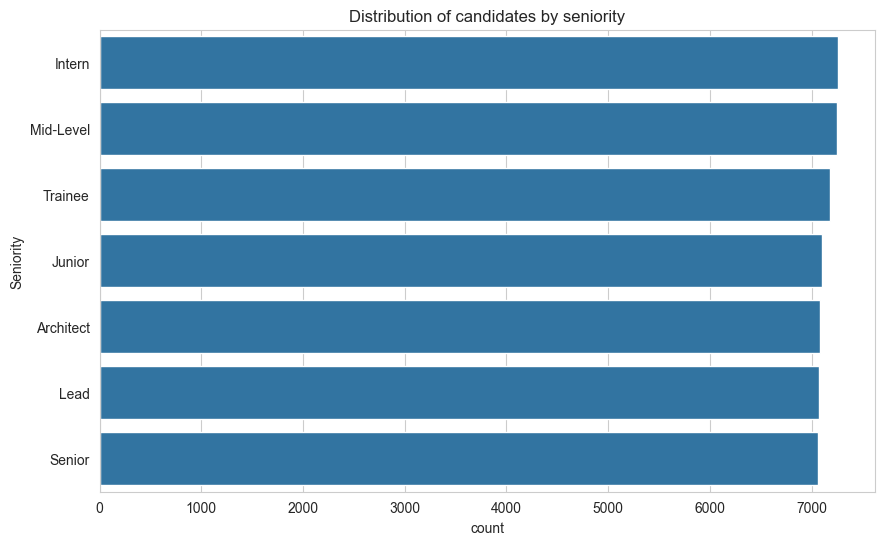

In [50]:
# Unique technologies
print("\nUnique technologies:", df['Technology'].nunique())
print(df['Technology'].unique())

# Unique seniority levels
print("\nUnique seniority levels:", df['Seniority'].nunique())
print(df['Seniority'].unique())

# Distribution of seniority
plt.figure(figsize=(10, 6))
sns.countplot(y='Seniority', data=df, order=df['Seniority'].value_counts().index)
plt.title('Distribution of candidates by seniority')
plt.show()

We examine the distribution of the evaluation scores and simulate a hiring rule to estimate the proportion of candidates that would be selected.

                YOE  Code Challenge Score  Technical Interview Score
count  50000.000000          50000.000000               50000.000000
mean      15.286980              4.996400                   5.003880
std        8.830652              3.166896                   3.165082
min        0.000000              0.000000                   0.000000
25%        8.000000              2.000000                   2.000000
50%       15.000000              5.000000                   5.000000
75%       23.000000              8.000000                   8.000000
max       30.000000             10.000000                  10.000000

Total theoretical hires: 6698
Hiring rate: 13.40%


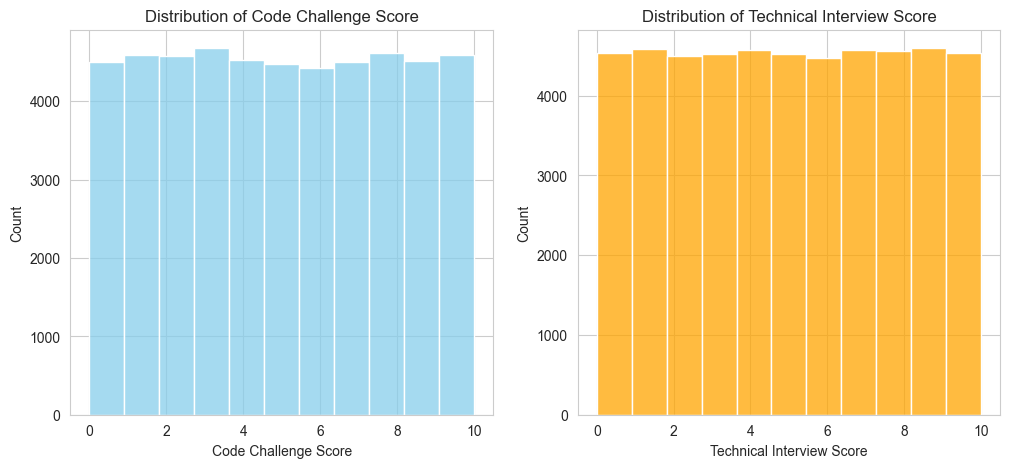

In [51]:
# Descriptive statistics
print(df[['YOE', 'Code Challenge Score', 'Technical Interview Score']].describe())

# Simulation of the "Hired" rule
# Rule: Both scores >= 7
hired_simulation = df[
    (df['Code Challenge Score'] >= 7) & 
    (df['Technical Interview Score'] >= 7)
]

print(f"\nTotal theoretical hires: {len(hired_simulation)}")
print(f"Hiring rate: {len(hired_simulation) / len(df) * 100:.2f}%")

# Score visualization
plt.figure(figsize=(12, 5))
plt.subplot(1, 2, 1)
sns.histplot(df['Code Challenge Score'], bins=11, kde=False, color='skyblue')
plt.title('Distribution of Code Challenge Score')

plt.subplot(1, 2, 2)
sns.histplot(df['Technical Interview Score'], bins=11, kde=False, color='orange')
plt.title('Distribution of Technical Interview Score')
plt.show()

In this step, we validate that there are no fully duplicated rows and search for potential identity duplicates (same first and last name but different email). Because the dataset was synthetically generated, we interpret these cases as homonyms (distinct people sharing the same name). The analysis reveals 854 potential homonym cases. In the absence of additional attributes to disambiguate individuals, we treat each unique email as a separate identity.

In [52]:
# 1. Look for exact duplicates (full row)
# If this is 0, it's perfect. If it is > 0, you should use df.drop_duplicates()
exact_duplicates = df.duplicated().sum()
print(f"Exact duplicates (full rows): {exact_duplicates}")

# 2. Look for possible identity duplicates (Same First Name + Last Name, Different Email)
# This helps justify why we use Email as the key instead of the Name
cols_name = ['First Name', 'Last Name']
duplicates_name = df[df.duplicated(subset=cols_name, keep=False)].sort_values(by=cols_name)

print(f"\nRecords that share First Name and Last Name: {len(duplicates_name)}")

# See an example of "homonyms" or "email change"
# We group by name to see how many different emails they have
name_email_check = df.groupby(['First Name', 'Last Name'])['Email'].nunique()
potential_same_person = name_email_check[name_email_check > 1]

print(f"People with the same name but different email: {len(potential_same_person)}")

if not potential_same_person.empty:
    print("\nExample of possible identity duplication:")
    name_example = potential_same_person.index[0]  # Take the first one
    display(df[(df['First Name'] == name_example[0]) & (df['Last Name'] == name_example[1])])

Exact duplicates (full rows): 0

Records that share First Name and Last Name: 1719
People with the same name but different email: 854

Example of possible identity duplication:


,First Name,Last Name,Email,Application Date,Country,YOE,Seniority,Technology,Code Challenge Score,Technical Interview Score
18124,Aaron,Rodriguez,linnie96@hotmail.com,2019-04-14,Tajikistan,10,Intern,Mulesoft,2,2
27734,Aaron,Rodriguez,ova5@yahoo.com,2022-04-14,Aruba,12,Junior,Adobe Experience Manager,1,0


Based on the analysis above, we derive the following business rules for the ETL process:

- **Rule 1**: Resolve email duplicates by retaining the most recent record.
- **Rule 2**: Convert application dates to the canonical `YYYY-MM-DD` format.
- **Rule 3**: Set `Hired` to `True` when both scores are greater than or equal to 7.